<a href="https://colab.research.google.com/github/AlejandroC-25/Ciencia-y-analitica-de-datos-A00835060-/blob/main/Actividad4EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 4**
Exploración de datos

---

*   NOMBRE: Alejandro Cena Peart
*   MATRÍCULA: A00835060

En esta actividad trabajarás con el archivo `personal_loan.csv`, basado en un conjunto de datos sobre clientes bancarios y su comportamiento financiero disponible en Kaggle.

Los datos fueron recopilados para analizar la posibilidad de que los clientes acepten un préstamo personal y contienen información demográfica, financiera y de productos bancarios asociados. Los indicadores incluidos son:

* `ID`: Identificador único del cliente
* `Age`: Edad del cliente (años completos)
* `Experience`: Experiencia laboral en años
* `Income`: Ingreso anual del cliente (en miles de dólares. Por ejemplo, 60 = 60,000 USD/año)
* `ZIP Code`: Código postal del cliente
* `Family`: Número de miembros de la familia
* `CCAvg`: Promedio de gastos mensuales con tarjeta de crédito (en miles de dólares)
* `Education`: Nivel educativo (1 = graduado, 2 = universitario, 3 = posgrado)
* `Mortgage`: Monto de hipoteca que posee el cliente (en miles de dólares)
* `Securities Account`: Indicador de si tiene cuenta de valores (1 = sí, 0 = no)
* `CD Account`: Indicador de si tiene cuenta de certificado de depósito (1 = sí, 0 = no)
* `Online`: Indicador de si usa los servicios bancarios en línea (1 = sí, 0 = no)
* `CreditCard`: Indicador de si es titular de tarjeta de crédito (1 = sí, 0 = no)
* `Personal Loan`: Si el cliente aceptó (1) o no (0) un préstamo personal. Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [1]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

1. Descarga el archivo: `personal_loan.csv` y guarda, en un dataframe (`loan_df`), todos sus registros.
* Haz que la columna `ID` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?

In [2]:
# Carga del archivo con ID como índice (desde el repositorio de GitHub)
url = "https://raw.githubusercontent.com/AlejandroC-25/Ciencia-y-analitica-de-datos-A00835060-/main/personal_loan.csv"
loan_df = pd.read_csv(url, index_col="ID")

# Resumen de tipos de datos
loan_df.info()

# Conteo explícito de columnas numéricas vs. texto
n_num = loan_df.select_dtypes(include="number").shape[1]
n_txt = loan_df.select_dtypes(exclude="number").shape[1]
print(f"Columnas numéricas: {n_num} | Columnas de texto: {n_txt}")

<class 'pandas.core.frame.DataFrame'>
Index: 5037 entries, 0 to 5036
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 5037 non-null   int64  
 1   Experience          5037 non-null   int64  
 2   Income              5037 non-null   int64  
 3   ZIP Code            5037 non-null   int64  
 4   Family              5037 non-null   int64  
 5   CCAvg               5037 non-null   float64
 6   Education           5037 non-null   float64
 7   Mortgage            5037 non-null   int64  
 8   Personal Loan       5037 non-null   object 
 9   Securities Account  5037 non-null   object 
 10  CD Account          5037 non-null   object 
 11  Online              5037 non-null   object 
 12  CreditCard          5037 non-null   object 
dtypes: float64(2), int64(6), object(5)
memory usage: 550.9+ KB
Columnas numéricas: 8 | Columnas de texto: 5


**El dataframe contiene 5,037 registros y 13 columnas. Al utilizar info(), se obtiene que existen 8 columnas de carácter numérico y 5 son de texto. Las de texto son variables binarias que contienen formatos mixtos, por ejemplo “Yes/No” junto con 0 y 1s y se unifican en la pregunta 3. Además, ZIP code y Education son variables numéricas pero estas deberían ser variables categóricas.**


# Limpieza

2. Obtén las estadísticas descriptivas de las variables numéricas y examina cuidadosamente los valores obtenidos de cada columna.
* Filtra el dataframe para visualizar los registros en que la edad supera los 100 años y elimínalos si no son pausibles.
* Analiza el resto de las variables y elimina aquellos registros que contengan valores inválidos o inconsistentes. Para cada acción que realices, justifica la decisión, explicando por qué consideras que el valor es incorrecto.
* ¿Cuántos registros se eliminaron (considerando todas las acciones de este ejercicio) y qué porcentaje representa respecto al total del dataframe inicial?

In [3]:
n_inicial = len(loan_df)

invalidos = (
    (loan_df["Age"] > 100)                          # edad imposible
    | (loan_df["Experience"] < 0)                   # experiencia negativa
    | (loan_df["Family"] < 1)                       # tamaño de familia no positivo
    | (~loan_df["Education"].isin([1, 2, 3]))       # nivel educativo fuera de catálogo
    | (loan_df["ZIP Code"] < 10000)                 # código postal con 4 dígitos
    | (loan_df["ZIP Code"] == 96651)                # código postal sospechoso
)

display(loan_df[loan_df["Age"] > 100])

loan_df = loan_df[~invalidos]

n_eliminados = n_inicial - len(loan_df)
print(f"Registros eliminados: {n_eliminados} ({n_eliminados / n_inicial:.2%} de {n_inicial})")

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
10,123,39,105,94710,4,2.4,3.0,0,0,0,0,No,0
250,144,6,29,94305,3,1.0,2.0,117,0,No,0,No,No
4800,130,7,73,94028,1,2.5,1.0,135,0,No,0,0,0


Registros eliminados: 66 (1.31% de 5037)


**Utilizando la función de describe() identifique los siguientes valores inválidos y elimine los registro correspondientes:**

**Age > 100 (3 registros: 123, 130 y 144 años): edades imposibles, datos mal capturados.
Experience < 0 (53 registros): la experiencia laboral se mide en años trabajados y no puede ser negativa.
Family < 1 (2 registros, con valores -3 y -1): una familia tiene al menos un miembro.
Education = 7.3 (1 registro): la variable sólo admite los valores 1, 2 y 3 (graduado, universitario, posgrado), y debe ser entera.**

**ZIP Code = 9307 (1 registro): un código postal estadounidense tiene 5 dígitos, por lo que este valor está mal capturado.**

**96651 (6 registros). código repetido y fuera del rango del resto de códigos postales, tratado como sospechoso y un posible error.**

**No eliminé valores altos de Income, CCAvg ni Mortgage, porque son outliers plausibles y no errores de captura.**

**En total se eliminaron 66 registros de 5,037, es decir, 1.31%.**




3. Obtén las estadísticas descriptivas de las variables de texto e imprime las frecuencias de sus categorías.
* Algunas columnas almacenan valores binarios utilizando distintos formatos. Unifica estos valores de manera consistente, asegurándote de que coincidan con la descripción de las variables al inicio de esta libreta.

In [4]:
#Estadisticas descriptivas
bin_cols = loan_df.select_dtypes(exclude="number").columns.tolist()
display(loan_df[bin_cols].describe())

# Frecuencias de categorías (antes de unificar)
for col in bin_cols:
    print(f"--- {col} ---")
    print(loan_df[col].value_counts(), "\n")

# Unificar al formato 1 = sí, 0 = no
mapa = {"Yes": 1, "No": 0, "1": 1, "0": 0}
for col in bin_cols:
    loan_df[col] = loan_df[col].map(mapa)

# Verificación: solo deben quedar 0 y 1, sin nulos
for col in bin_cols:
    print(col, loan_df[col].value_counts().to_dict(), "| nulos:", loan_df[col].isna().sum())

,Personal Loan,Securities Account,CD Account,Online,CreditCard
count,4971,4971,4971,4971,4971
unique,4,4,4,4,4
top,0,No,No,Yes,0
freq,3470,2689,2458,1699,2625


--- Personal Loan ---
Personal Loan
0      3470
No     1016
Yes     368
1       117
Name: count, dtype: int64 

--- Securities Account ---
Securities Account
No     2689
0      1763
Yes     390
1       129
Name: count, dtype: int64 

--- CD Account ---
CD Account
No     2458
0      2210
1       163
Yes     140
Name: count, dtype: int64 

--- Online ---
Online
Yes    1699
No     1626
1      1273
0       373
Name: count, dtype: int64 

--- CreditCard ---
CreditCard
0      2625
Yes     905
No      884
1       557
Name: count, dtype: int64 

Personal Loan {0: 4486, 1: 485} | nulos: 0
Securities Account {0: 4452, 1: 519} | nulos: 0
CD Account {0: 4668, 1: 303} | nulos: 0
Online {1: 2972, 0: 1999} | nulos: 0
CreditCard {0: 3509, 1: 1462} | nulos: 0


**Las cinco columnas de texto (Personal Loan, Securities Account, CD Account, Online y CreditCard) son variables binarias, pero cada una presenta cuatro categorías distintas (0, 1, Yes, No) porque los valores se registraron en formatos mixtos. Siguiendo la descripción de las variables (1 = sí, 0 = no), unifiqué los formatos tranformando Yes ->1 y No -> 0. Tras la conversión cada columna contiene únicamente los valores 0 y 1, sin valores nulos y sin pérdida de registros.**

4. Verifica si hay registros duplicados y si fuera así, elimínalos del dataframe.
* Asegúrate de reiniciar el índice para mantener una secuencia continua tras todas las eliminaciones de registros que hasta este punto se han realizado.

In [5]:
# Verificación de duplicados (se ignora el índice ID; se comparan todas las columnas)
n_duplicados = loan_df.duplicated().sum()
print(f"Registros duplicados: {n_duplicados}")

# Eliminación conservando la primera aparición
loan_df = loan_df.drop_duplicates()

# Reinicio del índice (secuencia continua tras todas las eliminaciones)
loan_df = loan_df.reset_index(drop=True)

# Verificación
print(f"Registros restantes: {len(loan_df)}")
print(f"Duplicados restantes: {loan_df.duplicated().sum()}")
print(f"Índice: {loan_df.index.min()} a {loan_df.index.max()}")

Registros duplicados: 36
Registros restantes: 4935
Duplicados restantes: 0
Índice: 0 a 4934


**Tras unificar los formatos binarios, verifique la existencia de registros duplicados comparando todas las columnas y encontré 36 duplicados. Esta verificación se hizo después de la unificación porque con formatos mezclados de Yes y 1 los registros idénticos no habían aparecido. Los elimine conservando la primera aparición y reinicie el índice para obtener un secuencia continua. El data frame quedó con 4,935 registros y en total se eliminaron 102 registros respecto a los 5,037 iniciales lo cual representa un 2.03%.**

5. Aunque hasta ahora se han considerado los tipos de datos inferidos por pandas, antes del EDA es recomendable revisar la naturaleza estadística de cada variable (continua, discreta, categórica, binaria, etc.) para aplicar el análisis adecuado.

* Efectúa las siguientes conversiones:
  - Nominal: ZIP Code - `object`
  - Ordinal: Education - `category` con orden 1, 2, 3
  - Binarias: Personal Loan, Securities Account, CD Account, Online, CreditCard - `category`
* Crea dos listas llamadas `num_cols` y `cat_cols` que contengan los nombres de las variables numéricas (int64, float64) y categóricas (object, category) del dataset, respectivamente.

In [6]:
# Nominal: ZIP Code -> object (código postal como etiqueta, no como cantidad)
loan_df["ZIP Code"] = loan_df["ZIP Code"].astype(str).astype(object)

# Ordinal: Education -> category con orden 1 < 2 < 3
# (primero a int para que las categorías sean 1, 2, 3 y no 1.0, 2.0, 3.0)
loan_df["Education"] = pd.Categorical(
    loan_df["Education"].astype(int), categories=[1, 2, 3], ordered=True
)

# Binarias -> category
bin_cols = ["Personal Loan", "Securities Account", "CD Account", "Online", "CreditCard"]
loan_df[bin_cols] = loan_df[bin_cols].astype("category")

# Listas de variables numéricas y categóricas
num_cols = loan_df.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = loan_df.select_dtypes(include=["object", "category"]).columns.tolist()

print("num_cols:", num_cols)
print("cat_cols:", cat_cols)
loan_df.dtypes

num_cols: ['Age', 'Experience', 'Income', 'Family', 'CCAvg', 'Mortgage']
cat_cols: ['ZIP Code', 'Education', 'Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']


,0
Age,int64
Experience,int64
Income,int64
ZIP Code,object
Family,int64
CCAvg,float64
Education,category
Mortgage,int64
Personal Loan,category
Securities Account,category


**Revisé la naturaleza estadística de cada variable y realicé las conversiones solicitadas: ZIP Code se trató como variable nominal (object), porque es un identificador y no una cantidad; Education como ordinal (category ordenada), ya que existe una jerarquía entre niveles educativos y Personal Loan, Securities Account, CD Account, Online y CreditCard como binarias (category). Con esto, num_cols agrupa las 6 variables numéricas (Age, Experience, Income, Family, CCAvg, Mortgage) y cat_cols las 7 categóricas (ZIP Code, Education y las 5 binarias). Family se mantiene como numérica discreta dado que es un conteo de personas.**

# Análisis exploratorio de datos (univariado)

6. Para el análisis de las variables numéricas obtén nuevamente las estadísticas descriptivas incluyendo los valores de simetría y curtosis.
* Clasifica las variables `Age`, `Income` y `Mortgage` según los valores observados de asimetría y curtosis.

In [7]:
# Estadísticas descriptivas ampliadas con asimetría (skewness) y curtosis (exceso)
desc = loan_df[num_cols].describe().T
desc["skewness"] = loan_df[num_cols].skew()
desc["kurtosis"] = loan_df[num_cols].kurt()
desc.round(3)

,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
Age,4935.0,45.568,11.312,24.0,36.0,46.0,55.0,67.0,-0.023,-1.161
Experience,4935.0,20.343,11.305,0.0,11.0,20.0,30.0,43.0,-0.016,-1.134
Income,4935.0,73.879,46.107,8.0,39.0,64.0,98.0,224.0,0.841,-0.048
Family,4935.0,2.392,1.148,1.0,1.0,2.0,3.0,4.0,0.160,-1.404
CCAvg,4935.0,1.937,1.749,0.0,0.7,1.5,2.6,10.0,1.593,2.630
Mortgage,4935.0,56.686,101.918,0.0,0.0,0.0,101.0,635.0,2.103,4.755


**Con base en la asimetría y la curtosis clasifiqué las variables solicitadas:**

**Age (asimetría = -0.02; curtosis = -1.16): distribución prácticamente simétrica y platicúrtica, es decir, más aplanada que la normal, con colas ligeras.**

**Income (asimetría = 0.84; curtosis = -0.05): sesgo positivo (a la derecha) moderado y curtosis cercana a la de la normal (mesocúrtica); aun así, la distribución se aparta de la normalidad por su asimetría.**

**Mortgage (asimetría = 2.10; curtosis = 4.76): sesgo positivo fuerte y leptocúrtica, con colas pesadas y un pico muy agudo. Esto refleja que la mayoría de los clientes no tiene hipoteca (valor 0) y unos pocos tienen montos muy altos.**

7. Genera un histograma para cada variable numérica, incluyendo la curva KDE y la curva de una distribución normal como referencia.
* Para las variables que clasificaste antes, compara los histogramas generados con los valores numéricos calculados y comenta si la forma de cada distribución coincide con lo esperado.
* Para cada variable, crea un gráfico de boxplot individual que incluya la media.
* Analiza la posición de la media respecto a la mediana. ¿Qué indica esta relación sobre el sesgo (asimetría) de la distribución?

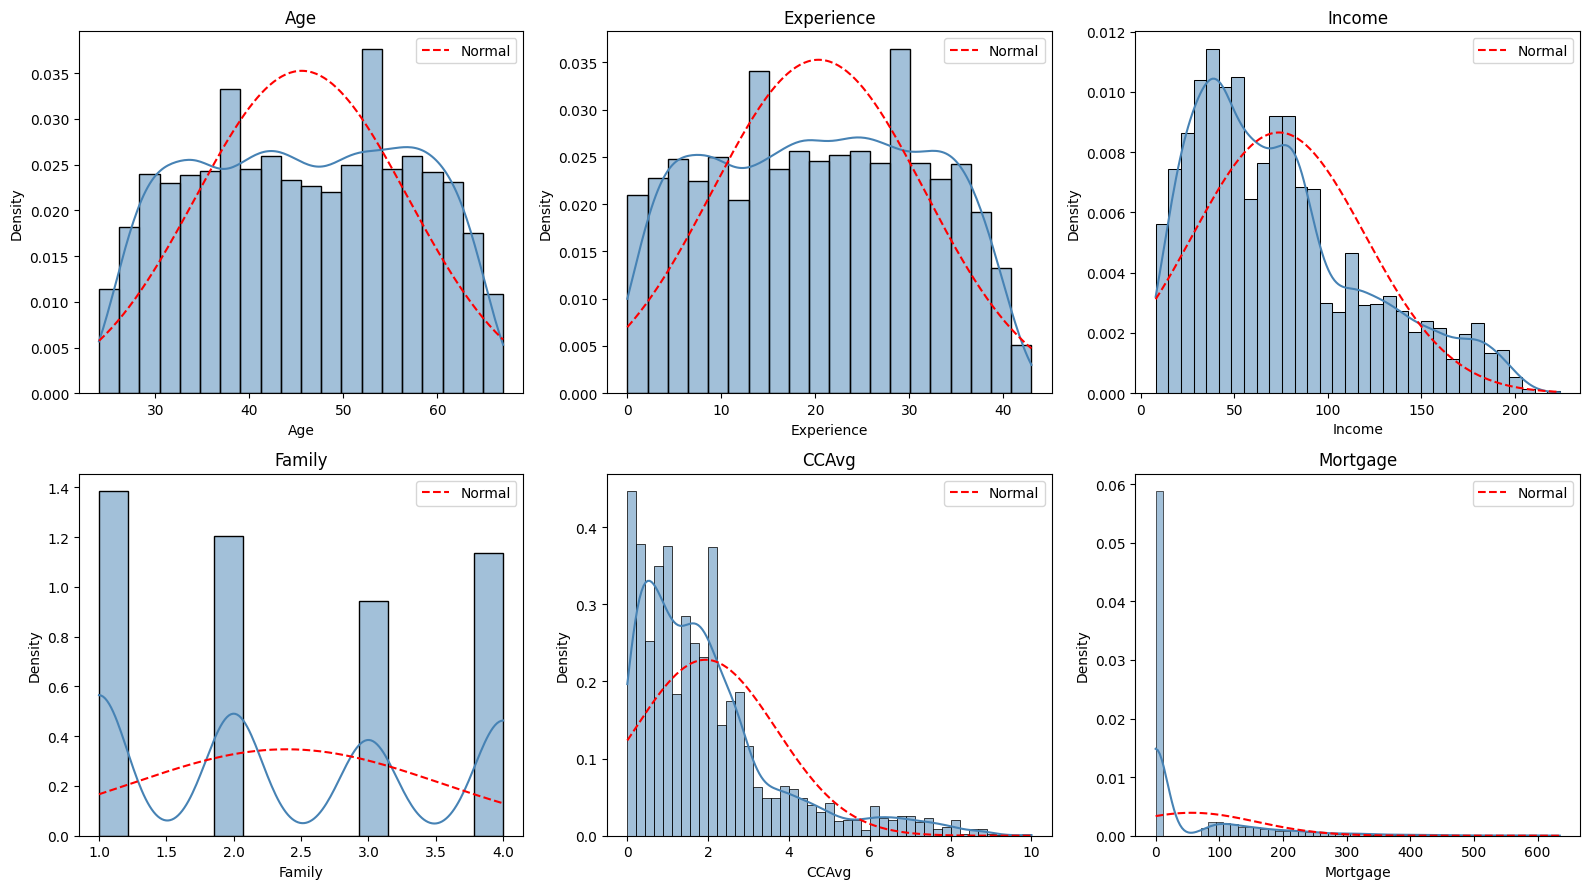

In [8]:
# 1) Histogramas con KDE y curva normal de referencia
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(loan_df[col], stat="density", kde=True, ax=ax, color="steelblue")
    x = np.linspace(loan_df[col].min(), loan_df[col].max(), 200)
    ax.plot(x, norm.pdf(x, loan_df[col].mean(), loan_df[col].std()),
            color="red", linestyle="--", label="Normal")
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.show()

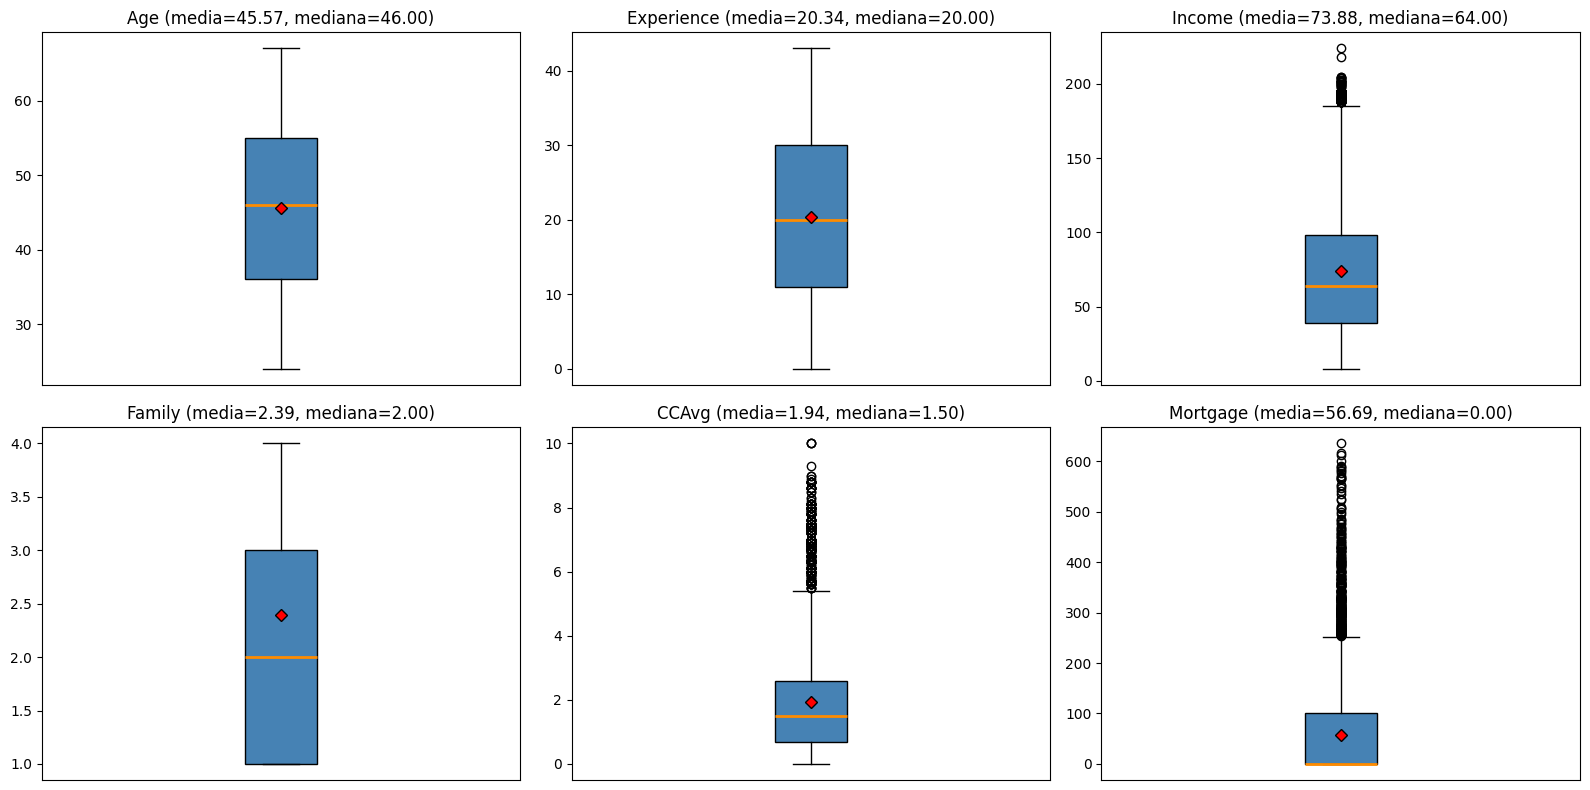

In [9]:
# 2) Boxplot individual por variable, con la media (rombo rojo)
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, num_cols):
    ax.boxplot(loan_df[col], showmeans=True, patch_artist=True,
               boxprops={"facecolor": "steelblue"},
               medianprops={"color": "darkorange", "linewidth": 2},
               meanprops={"marker": "D", "markerfacecolor": "red", "markeredgecolor": "black"})
    ax.set_xticks([])
    ax.set_title(f"{col} (media={loan_df[col].mean():.2f}, mediana={loan_df[col].median():.2f})")
plt.tight_layout()
plt.show()

**Los histogramas coinciden con lo esperado. Age es prácticamente plana y simétrica entre 24 y 67 años, sin pico central, y la normal de referencia sobreestima el centro y subestima las colas.**

**Income presenta una concentración en ingresos bajos-medios y una cola derecha moderada hasta 224, consistente con su asimetría de 0.84. Mortgage es la más alejada de la normalidad: la gran mayoría de los clientes alrededor del 69% tiene hipoteca 0 y existe una cola larga hasta 635, lo que concuerda con su asimetría de 2.10 y su curtosis de 4.76.**

**Media vs. mediana: En Age (45.6 vs. 46) y Experience (20.3 vs. 20) media y mediana casi coinciden, lo que indica simetría. En Income (73.9 vs. 64), CCAvg (1.94 vs. 1.5) y sobre todo Mortgage (56.7 vs. 0) la media es mayor que la mediana, señal de sesgo positivo.**

**Boxplots: Age, Experience y Family no presentan valores atípicos. Income, CCAvg y Mortgage muestran numerosos valores por encima del bigote superior, coherentes con su sesgo positivo, son valores plausibles y por ello se conservan.**

**Cuando la media es mayor que la mediana, la distribución tiene sesgo positivo, porque los valores extremos de la cola derecha elevan la media mientras que la mediana al ser robusta apenas se ve afectada. Cuando la media y mediana (Age y Experience) son casi iguales, la distribución es casi simetrica. una media menor que la mediana indicaria un sesgo negativo, caso que no se presenta en este conjunto de datos. La brecha es mayor en Mortage dado que tiene una media de 56 frente a una mediana de 0 lo cual es coherente con su asimetria de 2.1.**

8. Obtén las estadísticas descriptivas de las variables categóricas.
* Genera un gráfico de barras para cada variable. En las de alta cardinalidad, sólo incluye los 10 valores más relevantes.

,count,unique,top,freq
ZIP Code,4935,466,94720,163
Education,4935,3,1,2077
Personal Loan,4935,2,0,4456
Securities Account,4935,2,0,4420
CD Account,4935,2,0,4634
Online,4935,2,1,2948
CreditCard,4935,2,0,3485


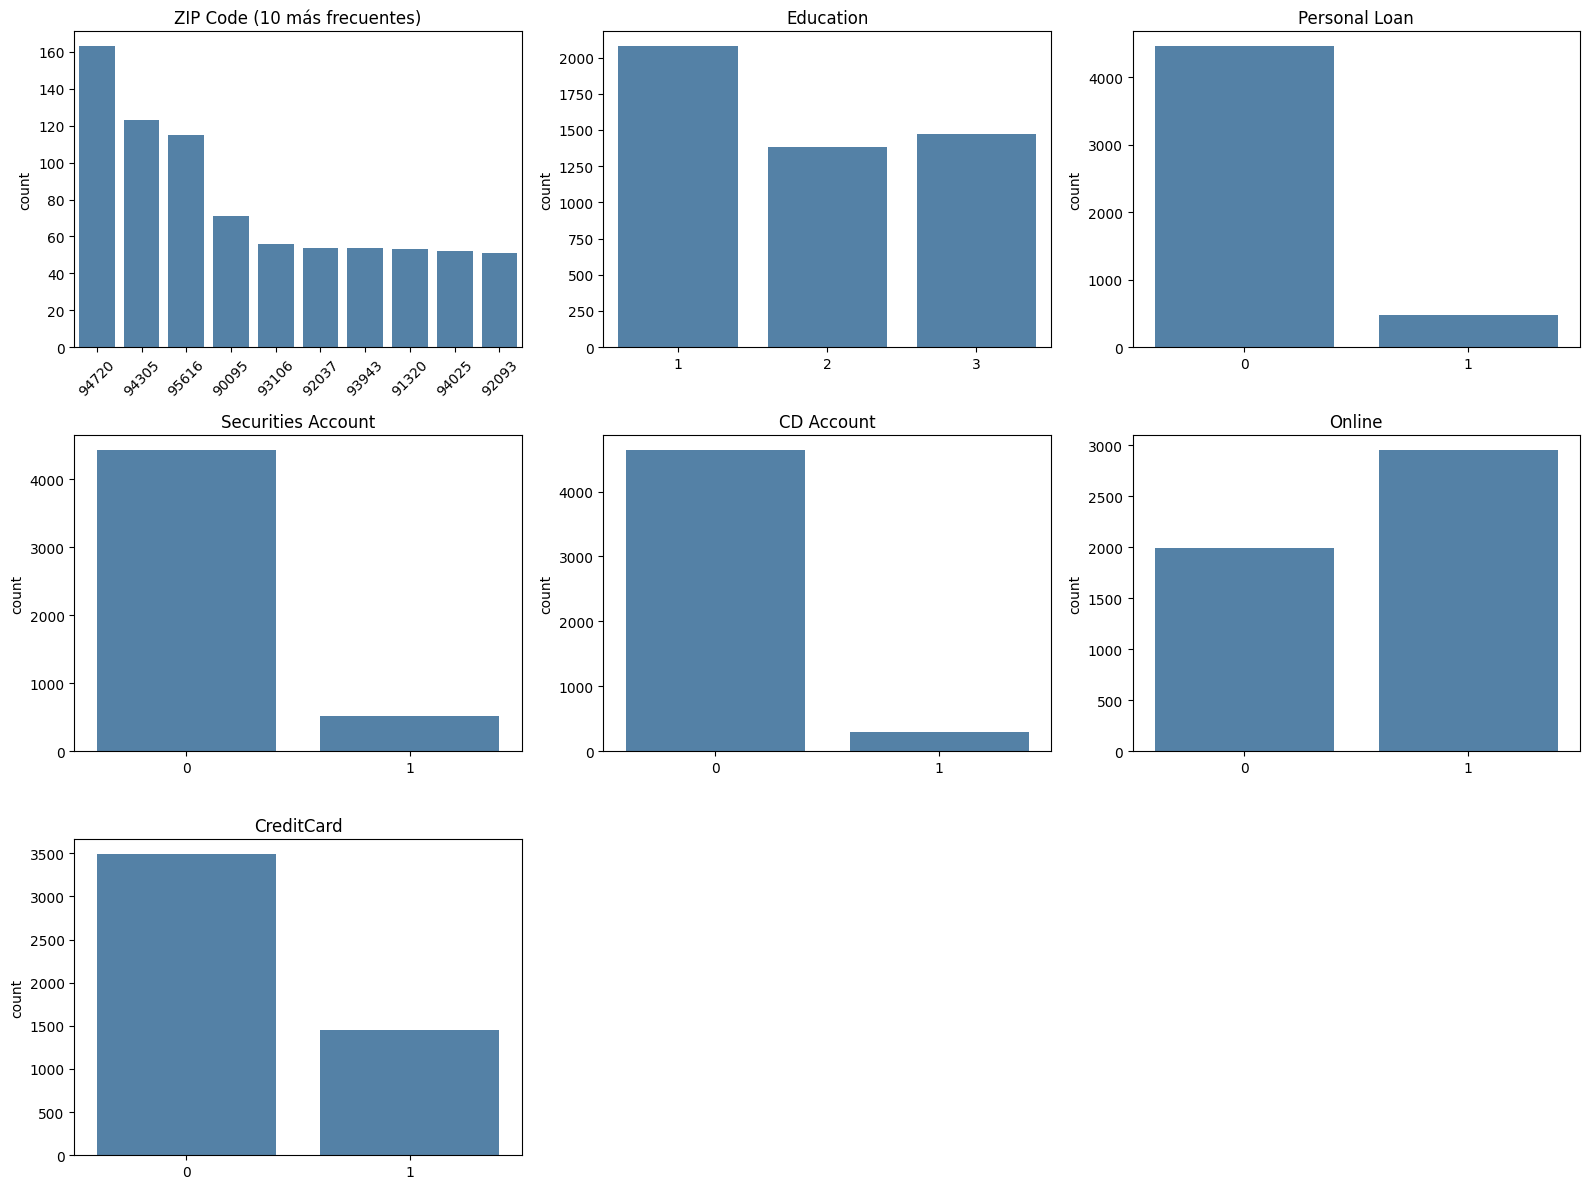

In [10]:
# Estadísticas descriptivas de las variables categóricas
display(loan_df[cat_cols].describe().T)

# Gráfico de barras por variable (ZIP Code: solo los 10 valores más frecuentes)
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for ax, col in zip(axes.flat, cat_cols):
    if col == "ZIP Code":
        orden = loan_df[col].value_counts().head(10).index
        titulo = "ZIP Code (10 más frecuentes)"
    else:
        orden = loan_df[col].cat.categories
        titulo = col
    sns.countplot(x=loan_df[col], order=orden, ax=ax, color="steelblue")
    ax.set_title(titulo)
    ax.set_xlabel("")
    if col == "ZIP Code":
        ax.tick_params(axis="x", rotation=45)

# Ocultar los ejes sobrantes de la cuadrícula 3x3
for ax in axes.flat[len(cat_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

**Las variables categóricas son ZIP Code, Education y las cinco binarias. ZIP Code es la única de alta cardinalidad, por lo que su gráfico muestra solo los 10 códigos más frecuentes, que juntos representan apenas el 16 % de los registros.**

**Entre las demás, la variable objetivo Personal Loan está fuertemente desbalanceada: solo el 9.7 % de los clientes aceptó el préstamo, frente al 90.3 % que no. Algo similar ocurre con CD Account (6.1 % con cuenta) y Securities Account (10.4 %), mientras que CreditCard es intermedia (29.4 % tiene tarjeta) y Online es la única donde predomina el valor 1 (59.7 % usa servicios en línea). En Education, el nivel 1 es el más frecuente (42.1 %), y los niveles 2 y 3 tienen proporciones similares (28.0 % y 29.9 %).**


# Análisis exploratorio de datos (bivariado)

9. Obtén la matriz de gráficos de dispersión (*scatter matrix*) de todas las variables numéricas.
* Observa las relaciones entre las variables, selecciona un par representativo y describe los patrones o tendencias que sean evidentes.
* Para cuantificar la fuerza y dirección de las relaciones observadas, genera un mapa de calor con los valores de correlación de *Pearson*. ¿El valor numérico obtenido del par seleccionado se corresponde con lo esperado?

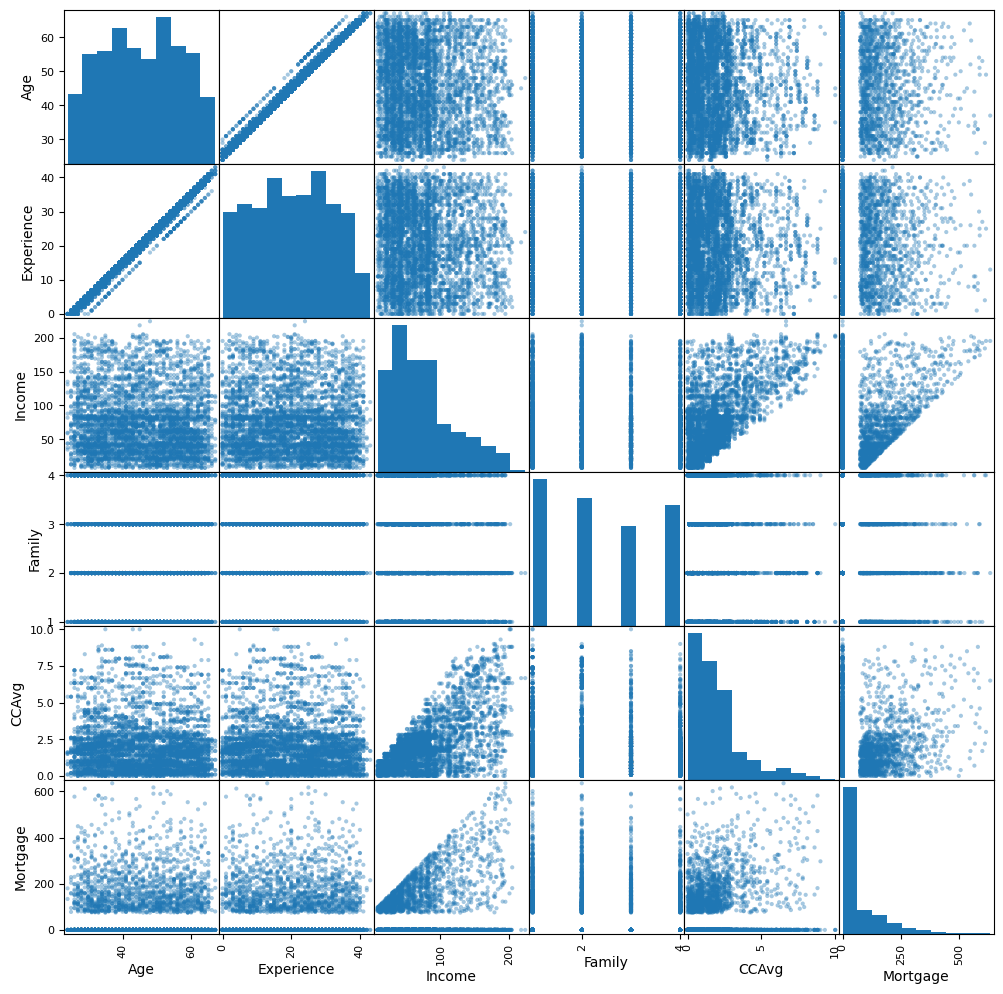

In [11]:
# Matriz de gráficos de dispersión de las variables numéricas
pd.plotting.scatter_matrix(loan_df[num_cols], figsize=(12, 12), diagonal="hist", alpha=0.4)
plt.show()

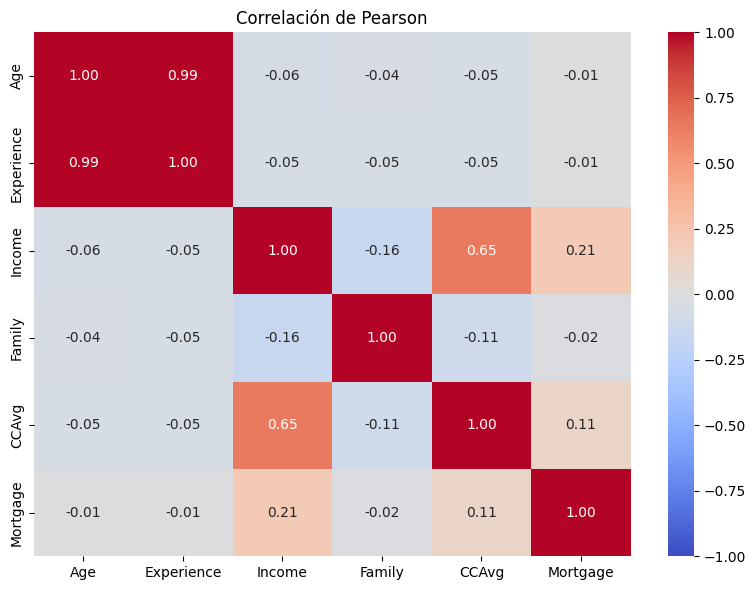

In [12]:
# Mapa de calor de correlación de Pearson
plt.figure(figsize=(8, 6))
corr = loan_df[num_cols].corr(method="pearson")
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación de Pearson")
plt.tight_layout()
plt.show()

**En la matriz de dispersión el par más evidente es Age y Experience: los puntos se alinean sobre una recta ascendente muy estrecha, es decir, a mayor edad mayor experiencia laboral, algo esperable porque la experiencia se acumula con los años de vida laboral. El mapa de calor de Pearson lo confirma con r = 0.994, una correlación positiva casi perfecta, por lo que el valor numérico sí corresponde con lo observado en el gráfico.**

**Otras relaciones destacables son Income y CCAvg (r = 0.65, positiva moderada) e Income y Mortgage (r = 0.21, positiva débil). El resto de pares presentan correlaciones cercanas a cero.**

10. Realiza un análisis de todas las variables del dataset con respecto a la variable de salida `Personal Loan`.
* Variables numéricas: Genera box plots para comparar la distribución de cada variable según los valores de `Personal Loan`.
* Variables categóricas (sin considerar `ZIP Code`): Genera gráficos de barras apiladas que muestren la distribución relativa de `Personal Loan` dentro de cada categoría de la variable.
* Para cada grupo de variables (numéricas y categóricas), comenta al menos un hallazgo o patrón relevante observado en los gráficos generados.


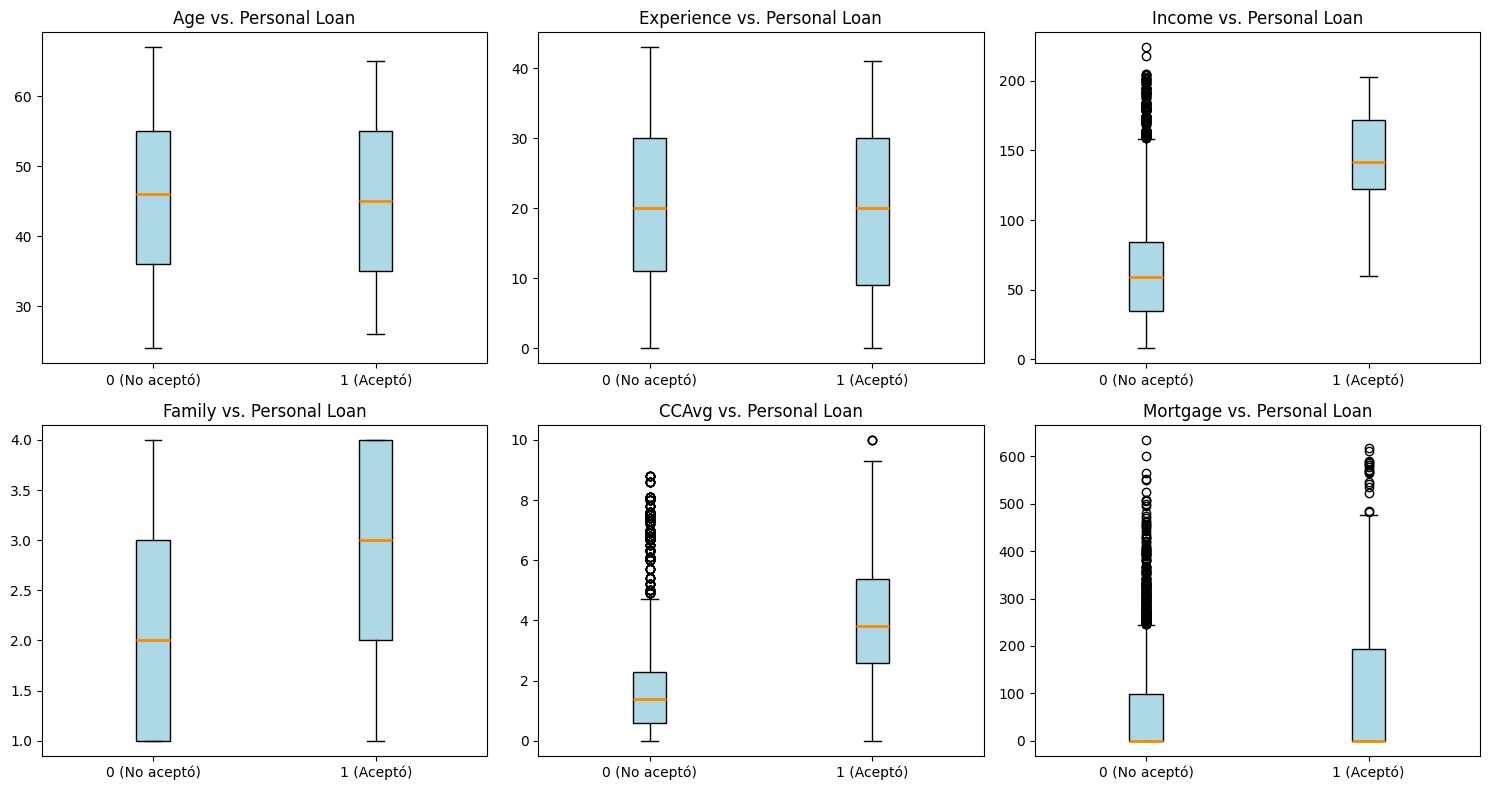

In [13]:
# 1) Variables numéricas: boxplot según Personal Loan
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, num_cols):
    grupos = [loan_df.loc[loan_df["Personal Loan"] == v, col] for v in (0, 1)]
    ax.boxplot(grupos, patch_artist=True, boxprops={"facecolor": "lightblue"},
               medianprops={"color": "darkorange", "linewidth": 2})
    ax.set_xticks([1, 2])
    ax.set_xticklabels(["0 (No aceptó)", "1 (Aceptó)"])
    ax.set_title(f"{col} vs. Personal Loan")
plt.tight_layout()
plt.show()

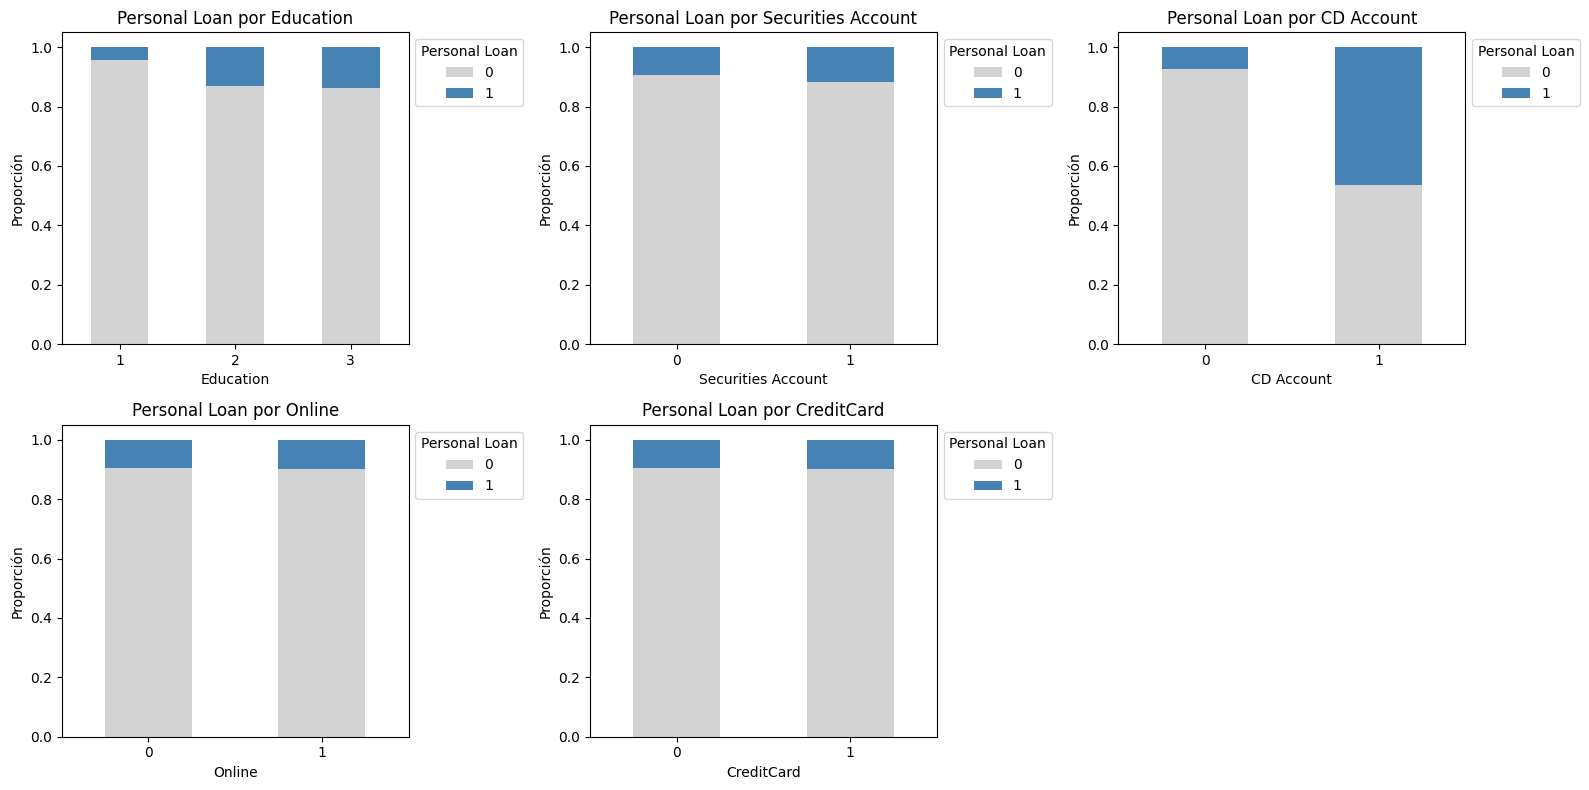

In [14]:
# 2) Variables categóricas (sin ZIP Code ni la propia variable objetivo): barras apiladas
cat_bivar = [c for c in cat_cols if c not in ("ZIP Code", "Personal Loan")]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, cat_bivar):
    prop = pd.crosstab(loan_df[col], loan_df["Personal Loan"], normalize="index")
    prop.plot(kind="bar", stacked=True, ax=ax, color=["lightgray", "steelblue"])
    ax.set_title(f"Personal Loan por {col}")
    ax.set_ylabel("Proporción")
    ax.tick_params(axis="x", rotation=0)
    ax.legend(title="Personal Loan", loc="upper left", bbox_to_anchor=(1, 1))
for ax in axes.flat[len(cat_bivar):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

**Variables numéricas**

**Income y CCAvg son las más discriminantes: los clientes que aceptaron el préstamo tienen una mediana de ingreso de 142 mil dólares frente a 59 mil de quienes no lo aceptaron, y un gasto mensual con tarjeta de 3.8 mil frente a 1.4 mil. Las cajas casi no se traslapan en el rango intercuartílico, lo que sugiere un alto poder predictivo. Family muestra una diferencia moderada (mediana de 3 miembros frente a 2). En Mortgage la mediana es 0 en ambos grupos, aunque quienes aceptaron presentan una caja más ancha y una media mayor (101 vs. 52). Age y Experience tienen distribuciones prácticamente idénticas en los dos grupos, por lo que no parecen relevantes para distinguirlos.**

**Variables categóricas**

**El hallazgo más fuerte es CD Account: el 46.5 % de los clientes con certificado de depósito aceptó el préstamo, contra el 7.3 % de quienes no lo tienen. En Education, los clientes con nivel 1 aceptan mucho menos (4.5 %) que los de nivel 2 y 3 (13.1 % y 13.9 %). Securities Account, Online y CreditCard muestran proporciones casi iguales entre categorías (diferencias de menos de 2.5 puntos), por lo que no parecen asociadas con la aceptación.**

---

**Declaración de uso de IA**

*   OpenAI. (2026). *ChatGPT (basado en GPT-4)* [Modelo de lenguaje grande], utilizado para consultar dudas acerca de temas especificos y conceptos. https://chat.openai.com/

*   Anthropic. (2026). *Claude* (Claude Sonnet 5.5) [Modelo de lenguaje grande], utilizado para generación de código, depuración y apoyo en mejorar la redacción de los análisis. https://claude.ai/

---